# Complete Graph Chow Polynomial Recurrence (Partition-Based)

Explorations for the $K_{n+1} \to K_n$ recurrence for Chow polynomials, using the **combinatorial translation** over set partitions $\Pi_n$ instead of the filtered flats $S_i(M^i)$.

**See:** `COMBINATORIAL_TRANSLATION.md` in this folder for the derivation.

$$H_{K_{n+1}}(y) = (1 - ny)\, H_{K_n}(y) + y \sum_{\pi \in \Pi_n} |\pi| \cdot H_{K_{|\pi|}}(y) \cdot H(\pi, y)$$

We reduce $K_{n+1}$ to $K_n$ by sequentially deleting the $n$ edges of a vertex star.

In [1]:
import sys
import os
import json

# Add project root and the-machine to path
current_dir = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(current_dir, "conclusion", "explorations on complete graphs")):
    project_root = current_dir
else:
    project_root = os.path.dirname(os.path.dirname(current_dir))
sys.path.insert(0, project_root)
sys.path.insert(0, os.path.join(project_root, "the-machine"))

from sage.all import *
from HM_module import *
from custom_matroid_functions import *

## Notation (from ALGORITHM.md)

- **$T_n$** = $\binom{n}{2}$ = number of edges in $K_n$
- **$M^i$** = matroid at step $i$ (indexed by edge labels $T_n+1 \leq i \leq T_{n+1}$)
- **$\Pi_n$** = set of all partitions of $\{1, \ldots, n\}$

## Partition-Based Reformulation

Instead of filtering flats by $S_i$, we sum over **all** partitions $\pi \in \Pi_n$ and weight each by $|\pi|$ (number of blocks). Each partition $\pi$ corresponds to a flat $F$ (disjoint union of cliques on the blocks).

## Labelled complete graph

Edges are labelled by **vertex addition**: add vertices 2, 3, ..., n. When adding vertex $j$, add edges $(1,j), (2,j), \ldots, (j-1,j)$ in that order:
- $(1,2) \to 1$; $(1,3) \to 2$, $(2,3) \to 3$; $(1,4) \to 4$, $(2,4) \to 5$, $(3,4) \to 6$; $(1,5) \to 7$, ...
- Star edges (incident to vertex $n+1$ in $K_{n+1}$) have the **highest labels**.

In [2]:
def T(n):
    """Triangular number: T_n = binom(n,2) = number of edges in K_n."""
    return n * (n - 1) // 2


def labelled_graph(i):
    """
    Return the labelled graph for matroid M_i (matroid with i edges).
    M1 = K2, M3 = K3, M6 = K4, M10 = K5, etc.
    Returns: (Graph, edge_to_label dict, label_to_edge dict)
    """
    i = int(i)
    if i == 0:
        return Graph(), {}, {}
    if i < 0:
        raise ValueError(f"i must be >= 0, got i={i}")
    n = int((1 + (1 + 8 * i) ** 0.5) / 2)
    T_n = T(n)
    edges = []
    edge_to_label = {}
    label_to_edge = {}
    label = 1
    for j in range(2, n + 1):
        for k in range(1, j):
            if label > i:
                break
            edges.append((k, j, label))
            edge_to_label[(k, j)] = label
            label_to_edge[label] = (k, j)
            label += 1
    for k in range(1, n + 1):
        if label > i:
            break
        edges.append((k, n + 1, label))
        edge_to_label[(k, n + 1)] = label
        label_to_edge[label] = (k, n + 1)
        label += 1
    G = Graph(edges)
    return G, edge_to_label, label_to_edge


def labelled_graph_for_Kn(n):
    """Wrapper: return the labelled graph for K_n = M(T_n)."""
    return labelled_graph(T(n))


def matroid_from_labelled_Kn(n):
    """Matroid M(K_n) = M(T_n)."""
    return Matroid(labelled_graph_for_Kn(n)[0])


def M_i(i):
    """Matroid M_i (matroid with i edges). M1=K2, M3=K3, M6=K4, M10=K5."""
    return Matroid(labelled_graph(i)[0])

## Partition-based recurrence

Map partition $\pi$ to flat $F$ (edges within blocks). Each block $B$ induces a clique on $B$.

In [3]:
def partition_to_flat(pi, label_to_edge, n):
    """Given partition pi of {1,...,n}, return flat F (frozenset of edge labels).
    pi: SetPartition or iterable of blocks (each block is iterable of vertices)."""
    block_of = {}
    for block in pi:
        block_set = frozenset(block)
        for v in block:
            block_of[v] = block_set
    F = set()
    for e, (u, v) in label_to_edge.items():
        if u <= n and v <= n and block_of.get(u) == block_of.get(v):
            F.add(e)
    return frozenset(F)


P = LaurentPolynomialRing(QQ, 'x')
x = P.gen()

def H_Kn(n):
    """Chow polynomial H_{K_n}. Returns poly in x."""
    return get_chow_polynomial(matroids.CompleteGraphic(n))


def H_M_restrict_F(M, F):
    """H_{M|F} - Chow polynomial of M restricted to F (matroid on the subgraph F)."""
    return get_chow_polynomial(M.delete(M.groundset() - F))


def recurrence_RHS_partitions(n):
    """RHS of H_{K_{n+1}} = (1-nx)H_{K_n} + sum over partitions.
    Uses partition-based formula: sum over pi in Pi_n of |pi| * H_{K_{|pi|}} * H(pi)."""
    M = M_i(T(n))  # M(K_n)
    _, _, label_to_edge = labelled_graph_for_Kn(n)
    base_term = (1 - n * x) * H_Kn(n)
    lattice_sum = P(0)
    for pi in SetPartitions(n):
        k = len(pi)  # number of blocks
        F = partition_to_flat(pi, label_to_edge, n)
        if k == 0:
            H_m = P(1)
        else:
            H_m = H_Kn(k)
        term = x * k * H_m * H_M_restrict_F(M, F)
        lattice_sum += term
    return base_term, lattice_sum, base_term + lattice_sum

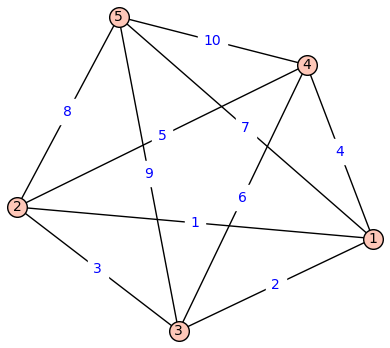

In [4]:
n = 5
labelled_graph(T(n))[0].show(edge_labels=True)

In [5]:
n = 7
base_part, lattice_part, rhs_part = recurrence_RHS_partitions(n)
#lhs = H_Kn(n + 1)
#print("LHS (H_{K_{n+1}}):", lhs)
print("RHS (partition-based):", rhs_part)
#print("LHS == RHS:", lhs == rhs_part)

RHS (partition-based): 1 + 4111*x + 111211*x^2 + 299882*x^3 + 111211*x^4 + 4111*x^5 + x^6


## Optional: valid_partitions_S_i (for comparison)

Partitions where vertex $i$ is the **strict minimum** of its block. Equivalent to flat-based $S_i$.

In [6]:
def valid_partitions_S_i(n, i):
    """Partitions where i is the strict minimum of its block. Equivalent to S_i."""
    return [pi for pi in SetPartitions(n) if any(min(B) == i for B in pi)]


# Example: n=4, i=3 (vertex 3 is the target)
print("Partitions for n=4 where vertex 3 is block minimum:")
for pi in valid_partitions_S_i(4, 3):
    print(" ", pi)

Partitions for n=4 where vertex 3 is block minimum:
  {{1, 2, 4}, {3}}
  {{1, 2}, {3, 4}}
  {{1, 2}, {3}, {4}}
  {{1, 4}, {2}, {3}}
  {{1}, {2, 4}, {3}}
  {{1}, {2}, {3, 4}}
  {{1}, {2}, {3}, {4}}


## Flat-based recurrence (from original notebook, for verification)

Compare with the original recurrence that iterates over $S_i$.

In [7]:
S_I_CACHE_PATH = os.path.join(project_root, "conclusion", "explorations on complete graphs", "s_i_cache.json")

def _load_s_i_cache():
    if not os.path.exists(S_I_CACHE_PATH):
        return {}
    try:
        with open(S_I_CACHE_PATH) as f:
            raw = json.load(f)
    except (json.JSONDecodeError, ValueError):
        return {}
    out = {}
    for k, v in raw.items():
        if "_" in k and isinstance(v, list):
            _, i = map(int, k.split("_"))
            out[i] = [frozenset(F) for F in v]
        elif isinstance(v, dict):
            for i_str, flats in v.items():
                out[int(i_str)] = [frozenset(F) for F in flats]
        elif isinstance(v, list):
            out[int(k)] = [frozenset(F) for F in v]
    return out

def _component_contains_active(label_to_edge, F, v_target, V_active, n):
    if not V_active:
        return False
    parent = {v: v for v in range(1, n + 1)}
    def find(u):
        if parent[u] != u:
            parent[u] = find(parent[u])
        return parent[u]
    def union(u, v):
        pu, pv = find(u), find(v)
        if pu != pv:
            parent[pu] = pv
    for e in F:
        if e in label_to_edge:
            u, v = label_to_edge[e]
            union(u, v)
    root_target = find(v_target)
    return any(find(v) == root_target for v in V_active)

def valid_flats_S_i(n, i, use_cache=True):
    n, i = int(n), int(i)
    if use_cache:
        cache = _load_s_i_cache()
        if i in cache:
            return cache[i]
    M_Kn = M_i(T(n))
    base_flats = list(M_Kn.lattice_of_flats())
    _, _, label_to_edge = labelled_graph_for_Kn(n)
    k_deleted = T(n + 1) - i
    v_target = n - k_deleted
    V_active = set(range(1, v_target)) if v_target > 1 else set()
    result = [F for F in base_flats if not _component_contains_active(label_to_edge, F, v_target, V_active, n)]
    if use_cache:
        cache = _load_s_i_cache()
        cache[i] = result
        raw = {str(k): [[int(e) for e in sorted(ff)] for ff in v] for k, v in sorted(cache.items())}
        with open(S_I_CACHE_PATH, "w") as f:
            json.dump(raw, f, indent=2)
    return result

def recurrence_RHS_flats(n):
    M = M_i(T(n))
    base_term = (1 - n * x) * H_Kn(n)
    lattice_sum = P(0)
    for i in range(T(n) + 1, T(n + 1) + 1):
        for F in valid_flats_S_i(n, i):
            rkF = M.rank(F)
            m = n - rkF
            if m < 0:
                continue
            H_m = P(1) if m == 0 else H_Kn(m)
            lattice_sum += x * H_m * H_M_restrict_F(M, F)
    return base_term, lattice_sum, base_term + lattice_sum

In [8]:
# Verify both methods give the same result
n = 5
_, _, rhs_part = recurrence_RHS_partitions(n)
_, _, rhs_flat = recurrence_RHS_flats(n)
print("Partition-based RHS:", rhs_part)
print("Flat-based RHS:", rhs_flat)
print("Match:", rhs_part == rhs_flat)

Partition-based RHS: 1 + 187*x + 732*x^2 + 187*x^3 + x^4
Flat-based RHS: 1 + 187*x + 732*x^2 + 187*x^3 + x^4
Match: True
